batchnorm toy but using pytorch
- https://arxiv.org/pdf/2105.07576

In [2]:
from helpers import *

# expanded similar to pytorch

In [31]:
class Linear:
	def __init__(self, fan_in, fan_out, bias=True):
		self.W = torch.randn((fan_in, fan_out)) * (5/3) / fan_in**0.5
		self.b = torch.zeros((fan_out)) if bias else None
	def __call__(self, x):
		if self.b == None:
			return x @ self.W
		return x @ self.W + self.b
	def parameters(self):
		return [self.W] + ([] if self.b == None else [self.b])

class BatchNorm1d:
	def __init__(self, dim, eps=1e-5, momentum=0.1):
		self.eps = eps
		self.momentum = momentum
		self.training = True # turn off later

		self.gamma = torch.ones(dim)
		self.beta = torch.zeros(dim)

		self.running_mean = torch.zeros(dim)
		self.running_var = torch.ones(dim)

	def __call__(self, x):
		if self.training:
			xmean = x.mean(0, keepdim=True)
			xvar = x.var(0, keepdim=True)
		else:
			xmean = self.running_mean
			xvar = self.running_var
		
		xhat = (x - xmean) / (xvar**0.5 + self.eps)
		self.out = self.gamma * xhat + self.beta

		if self.training:
			with torch.no_grad():
				self.running_mean = (1-self.momentum) * self.running_mean + self.momentum * xmean
				self.running_var = (1-self.momentum) * self.running_var + self.momentum * xvar
		
		return self.out
		
	def parameters(self):
		return [self.beta, self.gamma]

class Tanh:
	def __call__(self, x):
		self.out = torch.tanh(x)
		return self.out
	def parameters(self):
		return []

class Embedding:
	def __init__(self, num_embeddings, embedding_dim):
		self.n = num_embeddings
		self.dim = embedding_dim

		self.embeddings = torch.randn((self.n, self.dim))
	def __call__(self, token_indices):
		return self.embeddings[token_indices]
	def parameters(self):
		return [self.embeddings]

class Flatten:
	def __init__(self, start_dim = 1, end_dim = -1):
		self.start_dim = start_dim
		self.end_dim = end_dim
	def __call__(self, x):
		return torch.flatten(x, self.start_dim, self.end_dim)
	def parameters(self):
		return []

class Sequential:
	def __init__(self, *args):
		self.layers = {}
		for i, arg in enumerate(args):
			self.layers[i] = arg
		self.out = -1
		for p in self.parameters():
			p.requires_grad = True

	def __call__(self, x):
		for i, layer in self.layers.items():
			x = layer(x)
		self.out = x
		return self.out
	def __repr__(self):
		lines = [f"  ({k}): {v}" for k, v in self.layers.items()]
		return "Sequential(\n" + "\n".join(lines) + "\n)"
	def parameters(self):
		return [p for layer in self.layers.values() for p in layer.parameters()]

class CrossEntropyLoss:
	def __call__(self, logits, targets):
		# stability, everything <= 0. keeps exp from exploding
		logits = logits - logits.max(dim=1, keepdim=True).values
		counts = logits.exp()
		probs = counts / counts.sum(dim=1, keepdim=True)

		# probs: (Batch, probs across 27 letters)
		# probs[batch_i, target_letter_i]: (B,)
		return -probs[torch.arange(len(targets)), targets].log().mean()


class AdamOptimizer:
	def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
		self.params = list(params)
		self.lr, (self.b1, self.b2), self.eps = lr, betas, eps
		self.m = [torch.zeros_like(p) for p in self.params] # 1st moment
		self.v = [torch.zeros_like(p) for p in self.params] # 2nd moment
		self.t = 0
	
	def zero_grad(self):
		for p in self.params:
			p.grad = None

	@torch.no_grad()
	def step(self):
		self.t += 1

		# loop through all Weights, and respective 1st/2nd moment vals
		for p, m, v in zip(self.params, self.m, self.v):
			g = p.grad

			# weight is fixed/leaf
			if g is None:
				continue

			# m = b1*m + (1-b1)*g
			m = self.b1*m + (1-self.b1)*g
			# v = b2*v + (1-b2)*g²
			v = self.b2*v + (1-self.b2)*g**2

			m_hat = m / (1 - self.b1**self.t) # bias
			v_hat = v / (1 - self.b2**self.t)
			
			p -= self.lr * m_hat / (v_hat.sqrt() + self.eps)

In [32]:
batchsize = 32
embedding_size = 10
nhidden = 200
nin = embedding_size*context_size


mymodel = Sequential(
	Embedding(27, embedding_size),
	Flatten(),
	Linear(fan_in=nin, fan_out=nhidden), BatchNorm1d(nhidden), Tanh(),
	Linear(fan_in=nhidden, fan_out=nhidden), BatchNorm1d(nhidden), Tanh(),
	Linear(fan_in=nhidden, fan_out=nhidden), BatchNorm1d(nhidden), Tanh(),
	Linear(fan_in=nhidden, fan_out=nhidden), BatchNorm1d(nhidden), Tanh(),
	Linear(fan_in=nhidden, fan_out=nhidden), BatchNorm1d(nhidden), Tanh(),
	Linear(nhidden, 27)
)

criterion = CrossEntropyLoss()
optimizer = AdamOptimizer(mymodel.parameters(), lr=1e-4)

lossi = []
ud = []

for i in range(10000):
	ixs = torch.randint(0, Xtrain.shape[0], (batchsize,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]
	logits = mymodel(ctx)

	loss = criterion(logits, target)

	for layer in list(mymodel.layers.values()):
		if isinstance(layer, Tanh):
			layer.out.retain_grad()

	optimizer.zero_grad()
	loss.backward()
	optimizer.step()

	lossi.append(loss.item())
	with torch.no_grad():
		ud.append([((optimizer.lr*p.grad).std() / p.data.std()).log10().item() for p in mymodel.parameters()])
	# break


print(loss.item())

2.066783905029297


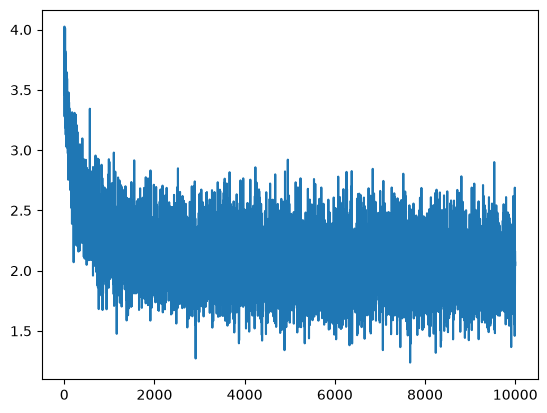

In [33]:
plt.plot(lossi)

layer 4 (      Tanh): mean +0.00, std 0.63, saturated: 3.62%
layer 7 (      Tanh): mean -0.00, std 0.64, saturated: 3.62%
layer 10 (      Tanh): mean -0.00, std 0.65, saturated: 3.23%
layer 13 (      Tanh): mean +0.00, std 0.65, saturated: 2.81%
layer 16 (      Tanh): mean -0.01, std 0.65, saturated: 3.58%


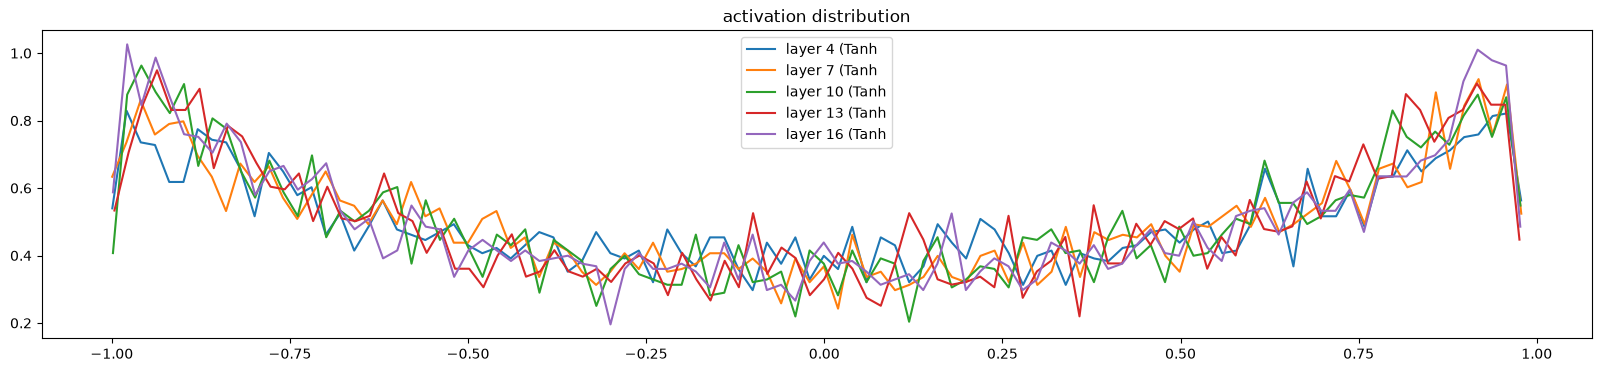

In [34]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(list(mymodel.layers.values())[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.detach()
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution');

layer 4 (      Tanh): mean +0.000000, std 3.951850e-03
layer 7 (      Tanh): mean -0.000000, std 3.576979e-03
layer 10 (      Tanh): mean -0.000000, std 3.389326e-03
layer 13 (      Tanh): mean -0.000000, std 3.158029e-03
layer 16 (      Tanh): mean -0.000003, std 3.563251e-03


Text(0.5, 1.0, 'gradient distribution')

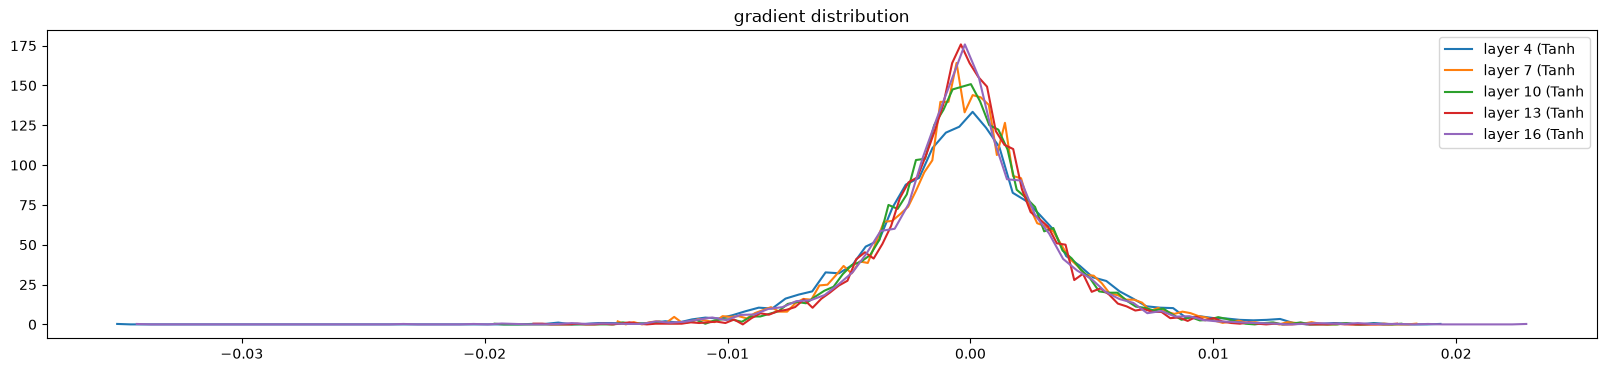

In [35]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(list(mymodel.layers.values())[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')

/tmp/ipykernel_3403469/1191663205.py:7: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /home/task_177834779994944/croot/libtorch_1778347848482/work/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))


weight   (27, 10) | mean +0.000000 | std 1.802009e-02 | grad:data ratio 1.847602e-02
weight  (30, 200) | mean +0.000042 | std 1.007524e-02 | grad:data ratio 3.328266e-02
weight (200, 200) | mean -0.000021 | std 8.139525e-03 | grad:data ratio 6.707777e-02
weight (200, 200) | mean +0.000041 | std 7.326964e-03 | grad:data ratio 6.041352e-02
weight (200, 200) | mean +0.000023 | std 6.834142e-03 | grad:data ratio 5.640182e-02
weight (200, 200) | mean -0.000015 | std 7.415036e-03 | grad:data ratio 6.108693e-02
weight  (200, 27) | mean +0.000000 | std 1.823024e-02 | grad:data ratio 8.607606e-02


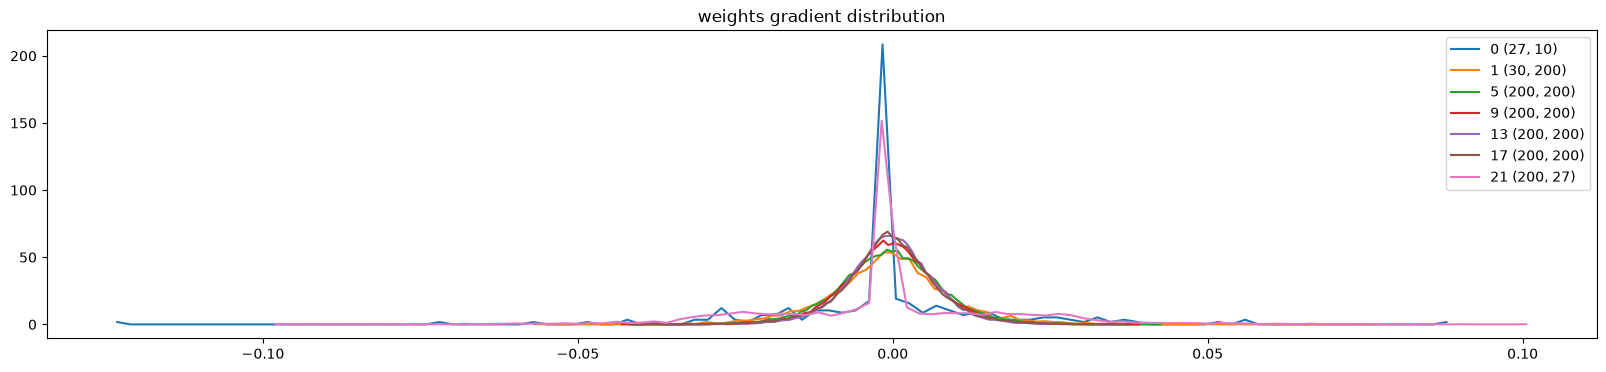

In [36]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(mymodel.parameters()):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

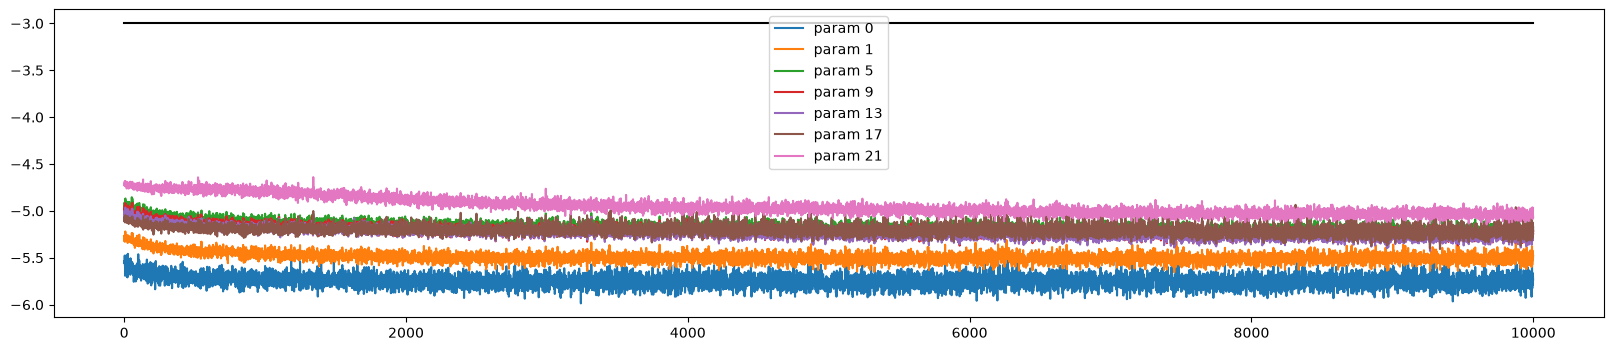

In [37]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(mymodel.parameters()):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);

In [39]:
alpha = "abcdefghijklmnopqrstuvwxyz."

for layer in mymodel.layers.values():
	if isinstance(layer, BatchNorm1d):
		layer.training = False

for i in range(20):
	ctx = torch.tensor([0] * context_size).unsqueeze(0)
	name = ""

	while len(name) < 20:
		logits = mymodel(ctx)
		probs = torch.softmax(logits, axis=1)
		cidx = torch.multinomial(probs, 1)
		c = alpha[cidx.item()]; name += c
		if c == ".":
			break
		ctx = torch.cat([ctx[:, 1:], cidx], dim=1)
	
	print(name)

damabelle.
egyb.
ton.
caminor.
madyina.
tyten.
ramyrinlee.
samiliana.
acretd.
agrosalynn.
n.
lzanne.
te.
alh.
caelyn.
ewme.
zaine.
faril.
daytylee.
delyn.


# condensed via off-shelf pytorch

In [40]:
embedding_size = 10
nhidden = 200
nin = embedding_size*context_size


mymodel = nn.Sequential(
	nn.Embedding(27, embedding_size), # token (aka index) to embeddings lookup
	nn.Flatten(), # flatten all embeddings into single vector
	nn.Linear(in_features=nin, out_features=nhidden),
	nn.BatchNorm1d(num_features=nhidden), # match prev out_features, norming across features
	nn.Tanh(),
	nn.Linear(in_features=nhidden, out_features=nhidden),
	nn.BatchNorm1d(num_features=nhidden),
	nn.Tanh(),
	nn.Linear(nhidden, 27)
)


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mymodel.parameters(), lr=1e-3)

lossi = []

for i in range(50000):
	ixs = torch.randint(0, Xtrain.shape[0], (32,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]
	logits = mymodel(ctx)

	loss = criterion(logits, target)

	optimizer.zero_grad()
	loss.backward() # calc .grad
	optimizer.step() # move

	lossi.append(loss.item())

print(loss.item())

1.8320399522781372


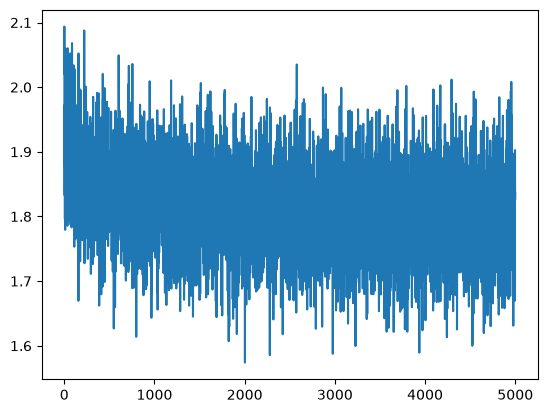

In [41]:
plt.plot(torch.tensor(lossi).view(-1, 5000).mean(0))

In [42]:
alpha = "abcdefghijklmnopqrstuvwxyz."

mymodel.eval() 

for i in range(20):
	ctx = torch.tensor([0] * context_size).unsqueeze(0)
	name = ""

	while len(name) < 20:
		logits = mymodel(ctx)
		probs = torch.softmax(logits, axis=1)
		cidx = torch.multinomial(probs, 1)
		c = alpha[cidx.item()]; name += c
		if c == ".":
			break
		ctx = torch.cat([ctx[:, 1:], cidx], dim=1)
	
	print(name)

stasing.
kariar.
rney.
alove.
lenee.
clar.
akarantormayshani.
miyah.
ddis.
na.
aoakloe.
sora.
ahatta.
poleth.
ezl.
aangelindyn.
phiscilee.
ajandra.
aany.
sha.
